This notebook is basically just a sanity check that the dataloader works

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make repo imports work from either repo root or notebooks/ cwd.
root = Path.cwd().resolve()
if not (root / "data_pipeline").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from data_pipeline import get_arithmetic_dataloader

In [4]:
dataloader = get_arithmetic_dataloader()

100%|██████████| 9.91M/9.91M [00:00<00:00, 35.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 23.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.60MB/s]


In [5]:
# VISUALIZATION (aka sanity check)
# This block is 100% chatgpt I'm not gonna lie
def visualize_batch(batch):
    cols = 4
    rows = 2
    fig, axes = plt.subplots(rows, cols, figsize=(15, 8))
    fig.suptitle("Data Batch", fontsize=16)

    for i in range(rows * cols):
        ax = axes[i // cols, i % cols]

        # Un-normalize for display
        ctx = batch["ctx_img"][i].squeeze().numpy() * 0.3081 + 0.1307
        tgt = batch["tgt_img"][i].squeeze().numpy() * 0.3081 + 0.1307

        # Create a combined image [Context | Target]
        combined = np.hstack((ctx, np.ones((28, 5)), tgt))  # Add white spacer

        ax.imshow(combined, cmap="gray")
        op_sign = (
            f"+{int(batch['op'][i])}"
            if batch["op"][i] > 0
            else f"{int(batch['op'][i])}"
        )
        ax.set_title(
            f"Ctx: {batch['ctx_label'][i]} | Op: {op_sign} | Tgt: {batch['tgt_label'][i]}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

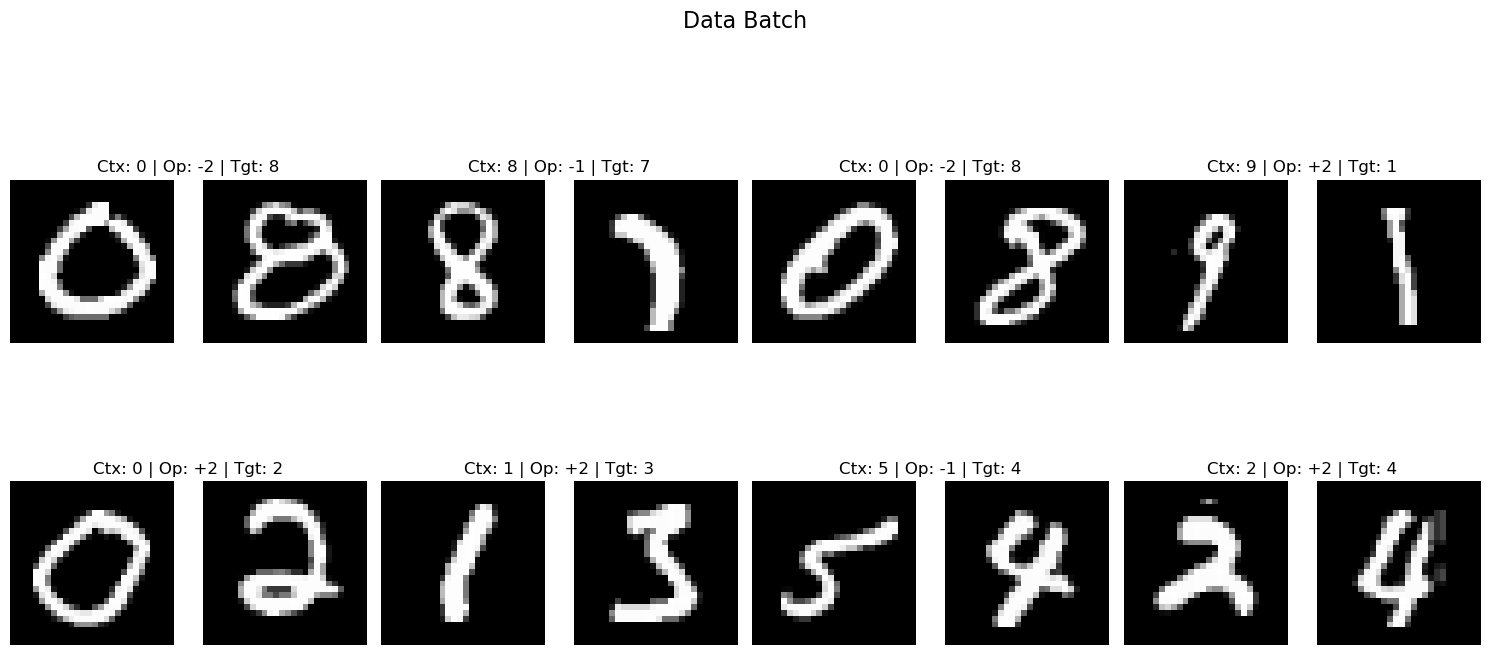

In [6]:
# Execute
batch = next(iter(dataloader))
visualize_batch(batch)

In [8]:
batch.keys()

dict_keys(['ctx_img', 'ctx_label', 'op', 'tgt_img', 'tgt_label'])

In [10]:
batch["op"]

tensor([-2., -1., -2.,  2.,  2.,  2., -1.,  2.,  1., -1.,  2.,  1., -2.,  1.,
         1., -2.,  2., -2.,  2.,  2.,  2.,  2., -1., -2.,  2., -2.,  1., -1.,
        -2.,  2.,  2., -1.,  1., -1., -2., -1., -1.,  1., -1., -1., -1., -2.,
        -2., -2., -1., -1.,  1., -1.,  2.,  2.,  1., -1., -1., -1., -1.,  2.,
         1., -2., -2.,  1., -1.,  1.,  1., -2.])